In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE    

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize

import skl2onnx
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType


In [3]:
#seeing how the heart disease dataset looks
df_heart= pd.read_csv('Dataset Heart Disease.csv')
print('Heart disease dataset:', df_heart.shape)

Heart disease dataset: (1048, 13)


In [4]:
df_heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048 entries, 0 to 1047
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           1048 non-null   int64  
 1   age                  1048 non-null   int64  
 2   sex                  1048 non-null   int64  
 3   chest pain type      1048 non-null   int64  
 4   resting bps          1048 non-null   int64  
 5   cholesterol          1048 non-null   float64
 6   fasting blood sugar  1048 non-null   int64  
 7   resting ecg          1048 non-null   int64  
 8   max heart rate       1048 non-null   int64  
 9   exercise angina      1048 non-null   int64  
 10  oldpeak              1048 non-null   float64
 11  ST slope             1048 non-null   int64  
 12  target               1048 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 106.6 KB


In [5]:
df_heart.head()

,Unnamed: 0,age,sex,chest pain type,resting bps,cholesterol,fasting blood sugar,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,0,40,1,2,140,289.0,0,0,172,0,0.0,1,0
1,1,49,0,3,160,180.0,0,0,156,0,1.0,2,1
2,2,37,1,2,130,283.0,0,1,98,0,0.0,1,0
3,3,48,0,4,138,214.0,0,0,108,1,1.5,2,1
4,4,54,1,3,150,195.0,0,0,122,0,0.0,1,0


In [6]:
#seeing how the gym members dataset looks
df_gym= pd.read_csv('gym_members_exercise_tracking.csv')
print('Gym dataset:', df_gym.shape)

Gym dataset: (973, 15)


In [7]:
df_gym.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    object 
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int

In [8]:
df_gym.head()

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [9]:
df_gym.columns = df_gym.columns.str.strip().str.lower().str.replace(" ", "_")
df_heart.columns = df_heart.columns.str.strip().str.lower().str.replace(" ", "_")

In [10]:
#calculates for every workout type what is 
# the max heart rate(bpm) and resting bpm

bpm_limits = df_gym.groupby('workout_type').agg(
    avg_max_bpm  = ('max_bpm', 'mean'),
    avg_rest_bpm = ('resting_bpm', 'mean'),
    avg_avg_bpm  = ('avg_bpm', 'mean')
).reset_index()

print(bpm_limits)

  workout_type  avg_max_bpm  avg_rest_bpm  avg_avg_bpm
0       Cardio   179.874510     61.988235   143.890196
1         HIIT   180.113122     62.687783   143.524887
2     Strength   179.027132     62.465116   144.313953
3         Yoga   180.606695     61.782427   143.267782


In [ ]:
# Rule to not pass 85% of maximum bpm 

df_gym['intensity_score'] = (
    df_gym['experience_level'] * 0.4 +        
    df_gym['workout_frequency_(days/week)'] * 0.3 +  
    df_gym['session_duration_(hours)'] * 0.3    
)

df_gym['fitness_level'] = pd.qcut(
    df_gym['intensity_score'],
    q=3,
    labels=['beginner', 'intermediate', 'advanced']
)

print(df_gym['fitness_level'].value_counts())
print(df_gym[['experience_level','workout_frequency_(days/week)',
              'session_duration_(hours)','intensity_score','fitness_level']].head(8))

fitness_level
beginner        325
advanced        325
intermediate    323
Name: count, dtype: int64
   experience_level  workout_frequency_(days/week)  session_duration_(hours)  \
0                 3                              4                      1.69   
1                 2                              4                      1.30   
2                 2                              4                      1.11   
3                 1                              3                      0.59   
4                 1                              3                      0.64   
5                 3                              5                      1.59   
6                 2                              3                      1.49   
7                 2                              3                      1.27   

   intensity_score fitness_level  
0            2.907      advanced  
1            2.390      advanced  
2            2.333  intermediate  
3            1.477      beginner  
4   

In [12]:
print(df_gym['fitness_level'].value_counts())
print(df_gym['fitness_level'].value_counts(normalize=True))  

# equilibrium between classes

fitness_level
beginner        325
advanced        325
intermediate    323
Name: count, dtype: int64
fitness_level
beginner        0.334018
advanced        0.334018
intermediate    0.331963
Name: proportion, dtype: float64


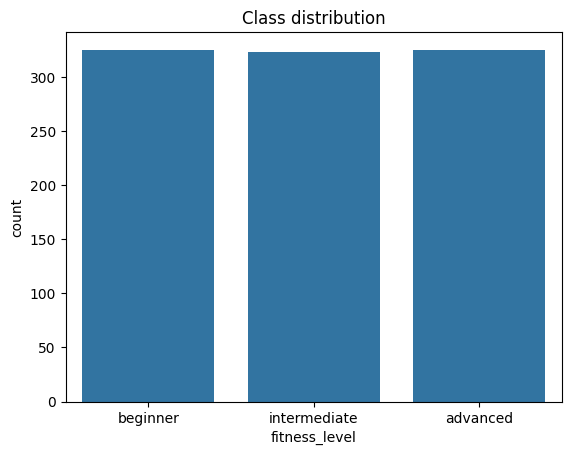

In [13]:
sns.countplot(x='fitness_level', data=df_gym)
plt.title('Class distribution')
plt.show()

In [14]:
le_level = LabelEncoder()
y_level  = le_level.fit_transform(df_gym['fitness_level'].astype(str))

le_gender = LabelEncoder()
df_gym['gender_enc'] = le_gender.fit_transform(df_gym['gender'])

X_profile = df_gym[[
    'age', 'gender_enc', 'weight_(kg)', 'bmi',
    'experience_level',              
    'workout_frequency_(days/week)', 
    'session_duration_(hours)',      
]]

X_train, X_test, y_train, y_test = train_test_split(
    X_profile, y_level, test_size=0.2, random_state=42, stratify=y_level
)

pipe = ImbPipeline([
    ('scaler', StandardScaler()),
    ('mlp',    MLPClassifier(
    hidden_layer_sizes=(32, 16),   
    max_iter=300,
    random_state=42,
    alpha=0.01,                   
    early_stopping=True,         
    validation_fraction=0.1,      
    n_iter_no_change=15,           
))
])

pipe.fit(X_train, y_train)
print(f"Train: {pipe.score(X_train, y_train):.2%}")
print(f"Test:  {pipe.score(X_test,  y_test):.2%}")
print(classification_report(y_test, pipe.predict(X_test), target_names=le_level.classes_))

Train: 89.20%
Test:  85.13%
              precision    recall  f1-score   support

    advanced       0.87      0.89      0.88        65
    beginner       0.86      0.95      0.91        65
intermediate       0.82      0.71      0.76        65

    accuracy                           0.85       195
   macro avg       0.85      0.85      0.85       195
weighted avg       0.85      0.85      0.85       195



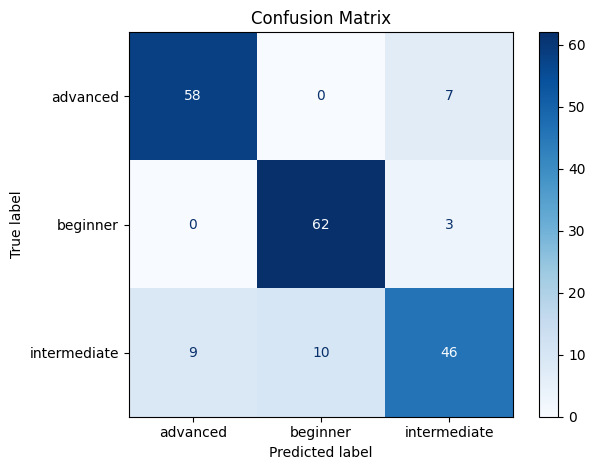

In [15]:
y_pred = pipe.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le_level.classes_)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

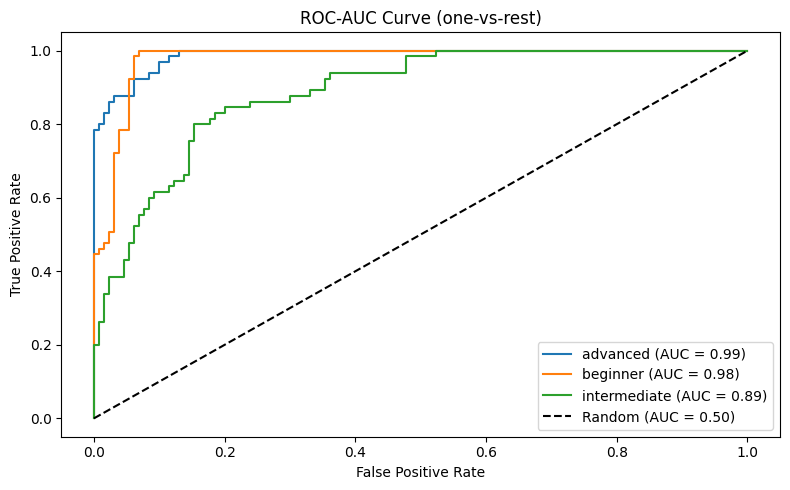

In [16]:
n_classes = len(le_level.classes_)
y_test_bin = label_binarize(y_test, classes=range(n_classes))
y_prob = pipe.predict_proba(X_test)  # probabilități per clasă

plt.figure(figsize=(8, 5))

for i, cls_name in enumerate(le_level.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc     = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{cls_name} (AUC = {roc_auc:.2f})')

# Linia diagonală = random classifier
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve (one-vs-rest)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:


WORKOUT_TO_WGER = {
    'Cardio'  : [10, 9],        # Abs + Legs → exerciții de cardio
    'HIIT'    : [9, 8, 11],     # Legs + Arms + Chest → full body
    'Strength': [8, 11, 12, 13],# Arms + Chest + Back + Shoulders
    'Yoga'    : [10, 12],       # Abs + Back → stretching/core
}

def get_exercises_from_wger(category_ids, language=2, limit=5):
    """
    Fetch exerciții din wger pentru o listă de category IDs.
    language=2 → engleză
    """
    exercises = []
    for cat_id in category_ids:
        url = "https://wger.de/api/v2/exercise/"
        params = {
            'format'  : 'json',
            'language': language,
            'category': cat_id,
            'limit'   : limit,
            'offset'  : 0,
        }
        resp = requests.get(url, params=params)
        if resp.status_code == 200:
            data = resp.json()
            for ex in data['results']:
                exercises.append({
                    'id'         : ex['id'],
                    'category_id': cat_id,
                    'description': ex.get('description', ''),
                })
    return exercises


def get_exercise_names(exercise_ids):
    """
     For every exercise ID it takes the name from exercise info.
    """
    names = {}
    for ex_id in exercise_ids:
        url  = f"https://wger.de/api/v2/exerciseinfo/{ex_id}/?format=json"
        resp = requests.get(url)
        if resp.status_code == 200:
            info = resp.json()
            # caută traducerea în engleză
            for trans in info.get('translations', []):
                if trans.get('language') == 2:
                    names[ex_id] = trans.get('name', f'Exercise {ex_id}')
                    break
            if ex_id not in names:
                names[ex_id] = f'Exercise {ex_id}'
    return names

In [18]:
def recommend(age, gender, weight, bmi, experience):
    # 1. Prezici fitness level din profil
    gender_enc = 1 if gender == 'Male' else 0
    features   = [[age, gender_enc, weight, bmi, experience,
                   df_gym['workout_frequency_(days/week)'].mean(),
                   df_gym['session_duration_(hours)'].mean()]]
    
    level = le_level.inverse_transform(pipe.predict(features))[0]
    
    # 2. Afișezi profilul
    print(f"\nProfil: {age} ani, {gender}, {weight}kg, BMI={bmi}")
    print(f"Nivel fitness detectat: {level.upper()}")
    
    # 3. Fetch exerciții din wger pentru nivelul detectat
    LEVEL_TO_WGER = {
    'beginner'    : ['Yoga', 'Cardio'],
    'intermediate': ['Cardio', 'Strength'],
    'advanced'    : ['HIIT', 'Strength'],
}
    workouts = LEVEL_TO_WGER[level]
    print(f"Workout-uri recomandate: {workouts}\n")
    
    for workout in workouts:
        cat_ids   = WORKOUT_TO_WGER.get(workout, [])
        exercises = get_exercises_from_wger(cat_ids, limit=3)
        ex_ids    = [e['id'] for e in exercises]
        names     = get_exercise_names(ex_ids)
        
        print(f"── {workout} ──")
        for ex in exercises:
            print(f"   • {names.get(ex['id'], f'ID {ex["id"]}')}")

# Test
recommend(age=25, gender='Male', weight=70, bmi=26, experience=1)


Profil: 25 ani, Male, 70kg, BMI=26
Nivel fitness detectat: BEGINNER
Workout-uri recomandate: ['Yoga', 'Cardio']

── Yoga ──
   • 2 Handed Kettlebell Swing
   • Barbell Ab Rollout
   • Abdominal Stabilization
   • Bent Over Dumbbell Rows
   • Bent Over Rowing
   • Bent Over Rowing Reverse
── Cardio ──
   • 2 Handed Kettlebell Swing
   • Barbell Ab Rollout
   • Abdominal Stabilization
   • Seated Hip Adduction
   • Barbell Hack Squats
   • Barbell Lunges Standing


In [ ]:

scaler_fitted = pipe['scaler']
mlp_fitted    = pipe['mlp']

model_export = {
    'scaler': {
        'mean' : scaler_fitted.mean_.tolist(),
        'scale': scaler_fitted.scale_.tolist(),
    },
    'mlp': {
        'coefs'     : [c.tolist() for c in mlp_fitted.coefs_],
        'intercepts': [i.tolist() for i in mlp_fitted.intercepts_],
        'classes'   : le_level.classes_.tolist(),
    },
    'meta': {
        'features': [
            'age', 'gender_enc', 'weight_(kg)', 'bmi',
            'experience_level', 'workout_frequency_(days/week)',
            'session_duration_(hours)'
        ],
        'workout_frequency_mean': float(df_gym['workout_frequency_(days/week)'].mean()),
        'session_duration_mean' : float(df_gym['session_duration_(hours)'].mean()),
    }
}

with open('fitness_model.json', 'w') as f:
    json.dump(model_export, f, indent=2)

print("Model exportat: fitness_model.json")

#Checking if it is saved correctly 
with open('fitness_model.json', 'r') as f:
    check = json.load(f)

print(f"Clase: {check['mlp']['classes']}")
print(f"Nr straturi: {len(check['mlp']['coefs'])}")
print(f"Features: {check['meta']['features']}")

Model exportat: fitness_model.json
Clase: ['advanced', 'beginner', 'intermediate']
Nr straturi: 3
Features: ['age', 'gender_enc', 'weight_(kg)', 'bmi', 'experience_level', 'workout_frequency_(days/week)', 'session_duration_(hours)']
